In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
# Create an images folder if you don't already have one
os.makedirs('images', exist_ok=True)
# Make our plots look clean and modern
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

In [2]:
df = pd.read_csv(r"C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\data\processed\data\employee_attrition_cleaned.csv")


In [3]:
# Count how many people stayed vs left
counts = df['Attrition'].value_counts()
percentages = df['Attrition'].value_counts(normalize=True) * 100
print(f"Stayed: {counts['No']} ({percentages['No']:.1f}%)")
print(f"Left:   {counts['Yes']} ({percentages['Yes']:.1f}%)")

Stayed: 1233 (83.9%)
Left:   237 (16.1%)


C:\Users\ar628\AppData\Local\Temp\ipykernel_15716\1650803831.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Attrition', palette=['#2b5c8f', "#a52c27"])


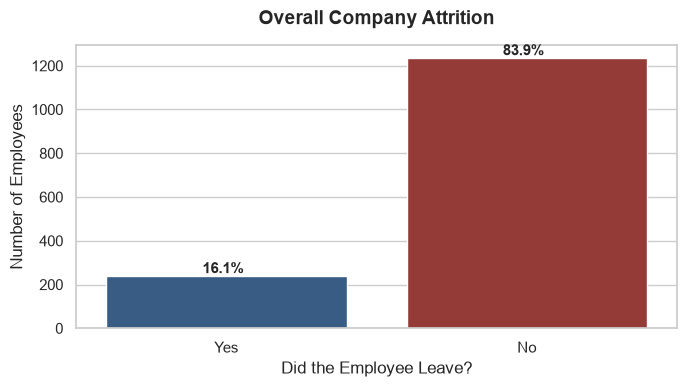

In [13]:
# Let's draw a simple bar chart
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='Attrition', palette=['#2b5c8f', "#a52c27"])
plt.title('Overall Company Attrition', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Did the Employee Leave?', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(pct, (p.get_x() + 0.32, p.get_height() + 15), fontweight='bold')
plt.tight_layout()
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\imagesattrition_plot.png', dpi=300)
plt.show()

Turnover percentage by Overtime:
Attrition    No   Yes
OverTime             
No         89.6  10.4
Yes        69.5  30.5


C:\Users\ar628\AppData\Local\Temp\ipykernel_15716\2121788926.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=overtime_attrition.index, y=overtime_attrition.values, palette=['#5cb85c', '#d9534f'])


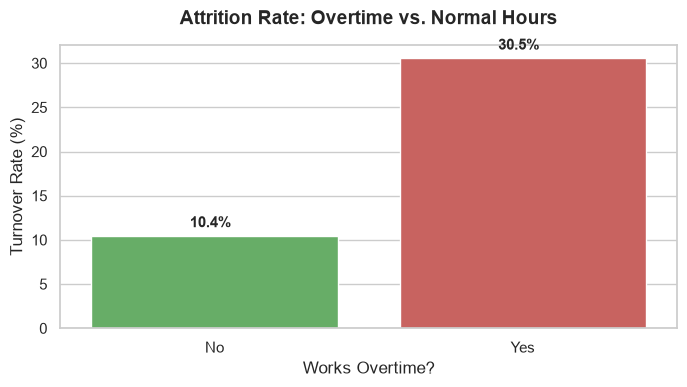

In [14]:
# Let's count how many people left in each group
crosstab = pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100
print("Turnover percentage by Overtime:")
print(crosstab.round(1))

# Grab just the percentage of people who said 'Yes' to leaving
overtime_attrition = crosstab['Yes']

# Plot the bar chart
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=overtime_attrition.index, y=overtime_attrition.values, palette=['#5cb85c', '#d9534f'])

plt.title('Attrition Rate: Overtime vs. Normal Hours', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Works Overtime?', fontsize=12)
plt.ylabel('Turnover Rate (%)', fontsize=12)

# Put the exact percentages on top of the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + 0.32, p.get_height() + 1), fontweight='bold')

plt.tight_layout()
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\images\attritionrate_overtime_normalhour.png', dpi=300)
plt.show()

Monthly Income vs. Leaving

Median Monthly Income:
Stayed: $5,204
Left:   $3,202


C:\Users\ar628\AppData\Local\Temp\ipykernel_15716\1393132683.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


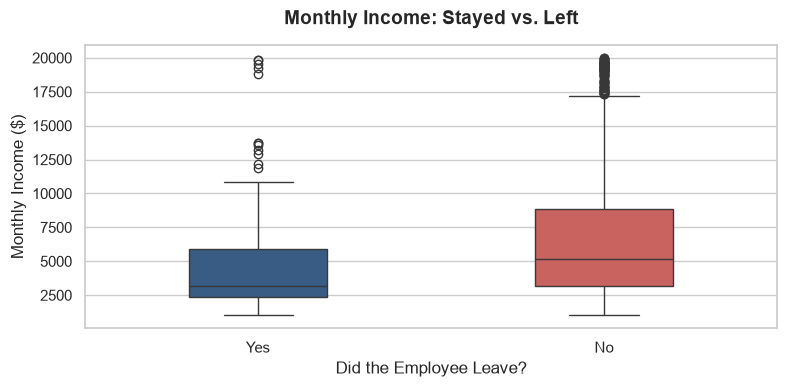

In [17]:
# Check median salary for both groups
median_salaries = df.groupby('Attrition')['MonthlyIncome'].median()
print("Median Monthly Income:")
print(f"Stayed: ${median_salaries['No']:,.0f}")
print(f"Left:   ${median_salaries['Yes']:,.0f}")

# Draw a clean boxplot to show the salary difference
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=df, 
    x='Attrition', 
    y='MonthlyIncome', 
    palette=['#2b5c8f', '#d9534f'],
    width=0.4
)

plt.title('Monthly Income: Stayed vs. Left', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Did the Employee Leave?', fontsize=12)
plt.ylabel('Monthly Income ($)', fontsize=12)

plt.tight_layout()
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\images\03_salary_vs_attrition.png', dpi=300)
plt.show()

Which Job Roles Have the Highest Turnover?

Turnover rate by Job Role:
JobRole
Sales Representative         39.8
Laboratory Technician        23.9
Human Resources              23.1
Sales Executive              17.5
Research Scientist           16.1
Manufacturing Director        6.9
Healthcare Representative     6.9
Manager                       4.9
Research Director             2.5
Name: Yes, dtype: float64


C:\Users\ar628\AppData\Local\Temp\ipykernel_15716\1070064765.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=role_attrition.values, y=role_attrition.index, palette='Reds_r')


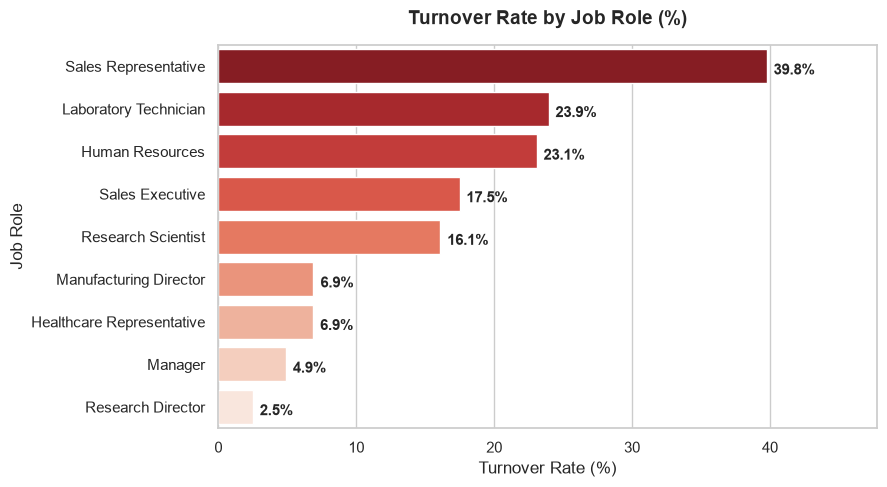

In [18]:
# Calculate the percentage of people who left in each job role
role_attrition = (
    pd.crosstab(df['JobRole'], df['Attrition'], normalize='index')['Yes'] * 100
).sort_values(ascending=False)

print("Turnover rate by Job Role:")
print(role_attrition.round(1))

# Horizontal bar chart so all the role titles fit cleanly
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=role_attrition.values, y=role_attrition.index, palette='Reds_r')

plt.title('Turnover Rate by Job Role (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Turnover Rate (%)', fontsize=12)
plt.ylabel('Job Role', fontsize=12)

# Put percentage numbers next to each bar
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}%", 
                (p.get_width() + 0.5, p.get_y() + 0.5), 
                va='center', fontweight='bold')

plt.xlim(0, max(role_attrition.values) + 8)
plt.tight_layout()
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\images\04_job_role_turnover.png', dpi=300)
plt.show()

At What Year Do Employees Quit?

Turnover rate by Company Tenure:
Tenure_Group
0-1 Year      34.9
2-3 Years     18.4
4-5 Years     13.1
6-10 Years    12.3
10+ Years      8.1
Name: Yes, dtype: float64


C:\Users\ar628\AppData\Local\Temp\ipykernel_15716\1493242387.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=tenure_attrition.index, y=tenure_attrition.values, palette='Blues_r')


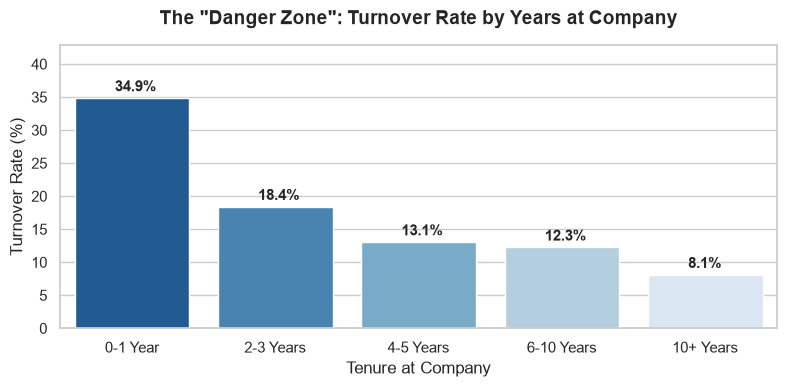

In [19]:
# Let's see the turnover rate based on Years at the Company
# We group tenure into clean buckets: 0-1 yr, 2-3 yrs, 4-5 yrs, 6-10 yrs, 10+ yrs
bins = [-1, 1, 3, 5, 10, 45]
labels = ['0-1 Year', '2-3 Years', '4-5 Years', '6-10 Years', '10+ Years']

df['Tenure_Group'] = pd.cut(df['YearsAtCompany'], bins=bins, labels=labels)

tenure_attrition = (
    pd.crosstab(df['Tenure_Group'], df['Attrition'], normalize='index')['Yes'] * 100
)

print("Turnover rate by Company Tenure:")
print(tenure_attrition.round(1))

# Plot the turnover curve
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=tenure_attrition.index, y=tenure_attrition.values, palette='Blues_r')

plt.title('The "Danger Zone": Turnover Rate by Years at Company', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure at Company', fontsize=12)
plt.ylabel('Turnover Rate (%)', fontsize=12)

# Add percentage labels
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + 0.28, p.get_height() + 1), 
                fontweight='bold')

plt.ylim(0, max(tenure_attrition.values) + 8)
plt.tight_layout()
plt.savefig(r'C:\Users\ar628\Downloads\Coding\Employee Attrition & Retention Diagnostic\images\05_tenure_danger_zone.png', dpi=300)
plt.show()